In [ ]:
import os
import re
import zipfile
import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
from google.colab import files
from IPython.display import display

# Upload dataset ZIP
uploaded = files.upload()

zip_path = next(
    name for name in uploaded.keys()
    if name.lower().endswith(".zip")
)

# Ekstraksi dataset
extract_dir = "/content/speedtest_extracted"
os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_dir)

# Ambil seluruh file Excel
all_files = sorted(
    glob.glob(
        os.path.join(extract_dir, "**", "*.xlsx"),
        recursive=True
    )
)

print("Nama ZIP:", zip_path)
print("Jumlah file Excel:", len(all_files))

for file_path in all_files:
    print(os.path.basename(file_path))

Saving 3TID_03_Speedtest Data by Ookla (2).zip to 3TID_03_Speedtest Data by Ookla (2).zip
Nama ZIP: 3TID_03_Speedtest Data by Ookla (2).zip
Jumlah file Excel: 22
3TID_03_Speedtest Data by Ookla1.xlsx
3TID_03_Speedtest Data by Ookla2.xlsx
3TID_03_Speedtest Data by Ookla3.xlsx
3TID_03_Speedtest Data by Ookla4.xlsx
3TID_03_Speedtest Data by Ookla_2021_1.xlsx
3TID_03_Speedtest Data by Ookla_2021_2.xlsx
3TID_03_Speedtest Data by Ookla_2021_3.xlsx
3TID_03_Speedtest Data by Ookla_2021_4.xlsx
3TID_03_Speedtest Data by Ookla_2022_1.xlsx
3TID_03_Speedtest Data by Ookla_2022_2.xlsx
3TID_03_Speedtest Data by Ookla_2022_3.xlsx
3TID_03_Speedtest Data by Ookla_Mobile_2020_1.xlsx
3TID_03_Speedtest Data by Ookla_Mobile_2020_2.xlsx
3TID_03_Speedtest Data by Ookla_Mobile_2020_3.xlsx
3TID_03_Speedtest Data by Ookla_Mobile_2020_4.xlsx
3TID_03_Speedtest Data by Ookla_Mobile_2021_1.xlsx
3TID_03_Speedtest Data by Ookla_Mobile_2021_2.xlsx
3TID_03_Speedtest Data by Ookla_Mobile_2021_3.xlsx
3TID_03_Speedtest Dat

# Pemeriksaan seluruh file dan tipe **data**

In [ ]:
file_details = []
schema_details = []

for file_path in all_files:
    df = pd.read_excel(file_path)
    nama_file = os.path.basename(file_path)

    # Informasi tipe koneksi dan periode
    is_mobile = "Mobile" in nama_file

    match = re.search(r"(20\d{2})_(\d)", nama_file)

    if match:
        tahun = int(match.group(1))
        kuartal = int(match.group(2))
    else:
        match_fixed = re.search(
            r"Ookla([1-4])\.xlsx$",
            nama_file
        )

        if match_fixed:
            tahun = 2020
            kuartal = int(match_fixed.group(1))
        else:
            raise ValueError(
                f"Periode tidak dikenali: {nama_file}"
            )

    tipe = "Mobile" if is_mobile else "Fixed"

    file_details.append({
        "Nama file": nama_file,
        "Tipe koneksi": tipe,
        "Periode": f"{tahun}-Q{kuartal}",
        "Jumlah baris": len(df),
        "Jumlah kolom": len(df.columns),
        "Missing value": int(df.isna().sum().sum()),
        "Duplikat dalam file": int(df.duplicated().sum())
    })

    for kolom in df.columns:
        schema_details.append({
            "Nama file": nama_file,
            "Kolom": kolom,
            "Tipe data": str(df[kolom].dtype),
            "Missing value": int(df[kolom].isna().sum())
        })

file_report = pd.DataFrame(file_details)
schema_report = pd.DataFrame(schema_details)

print("RINGKASAN PEMERIKSAAN FILE")
display(file_report)

print("TIPE DATA DAN MISSING VALUE SETIAP KOLOM")
display(schema_report)

print("TOTAL BARIS DARI SELURUH FILE:",
      file_report["Jumlah baris"].sum())

print("TOTAL MISSING VALUE:",
      file_report["Missing value"].sum())

print("TOTAL DUPLIKAT DALAM FILE:",
      file_report["Duplikat dalam file"].sum())

RINGKASAN PEMERIKSAAN FILE


,Nama file,Tipe koneksi,Periode,Jumlah baris,Jumlah kolom,Missing value,Duplikat dalam file
0,3TID_03_Speedtest Data by Ookla1.xlsx,Fixed,2020-Q1,234,11,0,0
1,3TID_03_Speedtest Data by Ookla2.xlsx,Fixed,2020-Q2,235,11,0,0
2,3TID_03_Speedtest Data by Ookla3.xlsx,Fixed,2020-Q3,234,11,0,0
3,3TID_03_Speedtest Data by Ookla4.xlsx,Fixed,2020-Q4,236,11,0,0
4,3TID_03_Speedtest Data by Ookla_2021_1.xlsx,Fixed,2021-Q1,235,11,0,0
5,3TID_03_Speedtest Data by Ookla_2021_2.xlsx,Fixed,2021-Q2,236,11,0,0
6,3TID_03_Speedtest Data by Ookla_2021_3.xlsx,Fixed,2021-Q3,236,11,0,0
7,3TID_03_Speedtest Data by Ookla_2021_4.xlsx,Fixed,2021-Q4,236,11,0,0
8,3TID_03_Speedtest Data by Ookla_2022_1.xlsx,Fixed,2022-Q1,238,11,0,0
9,3TID_03_Speedtest Data by Ookla_2022_2.xlsx,Fixed,2022-Q2,238,11,0,0


TIPE DATA DAN MISSING VALUE SETIAP KOLOM


,Nama file,Kolom,Tipe data,Missing value
0,3TID_03_Speedtest Data by Ookla1.xlsx,Name,object,0
1,3TID_03_Speedtest Data by Ookla1.xlsx,Number of Records,int64,0
2,3TID_03_Speedtest Data by Ookla1.xlsx,Devices,int64,0
3,3TID_03_Speedtest Data by Ookla1.xlsx,Tests,int64,0
4,3TID_03_Speedtest Data by Ookla1.xlsx,Avg. Avg U Kbps,int64,0
...,...,...,...,...
237,3TID_03_Speedtest Data by Ookla_Mobile_2022_3....,Avg Lat Ms,int64,0
238,3TID_03_Speedtest Data by Ookla_Mobile_2022_3....,Avg. Pop2005,int64,0
239,3TID_03_Speedtest Data by Ookla_Mobile_2022_3....,Rank Upload,int64,0
240,3TID_03_Speedtest Data by Ookla_Mobile_2022_3....,Rank Download,int64,0


TOTAL BARIS DARI SELURUH FILE: 5084
TOTAL MISSING VALUE: 0
TOTAL DUPLIKAT DALAM FILE: 0


# Penggabungan, pembersihan, dan statistika **deskriptif**

In [ ]:
frames = []

for file_path in all_files:
    df = pd.read_excel(file_path)
    nama_file = os.path.basename(file_path)

    # Seragamkan nama kolom yang tidak konsisten
    df.columns = df.columns.str.strip()

    df = df.rename(columns={
        "Number of Record": "Number of Records"
    })

    # Identifikasi tipe koneksi
    tipe = (
        "Mobile"
        if "Mobile" in nama_file
        else "Fixed"
    )

    # Identifikasi periode
    match = re.search(r"(20\d{2})_(\d)", nama_file)

    if match:
        tahun = int(match.group(1))
        kuartal = int(match.group(2))
    else:
        match_fixed = re.search(
            r"Ookla([1-4])\.xlsx$",
            nama_file
        )

        tahun = 2020
        kuartal = int(match_fixed.group(1))

    df["Connection Type"] = tipe
    df["Year"] = tahun
    df["Quarter"] = kuartal
    df["Period"] = f"{tahun}-Q{kuartal}"
    df["Source File"] = nama_file

    frames.append(df)

# Gabungkan semua file
raw = pd.concat(frames, ignore_index=True)

# Pastikan kecepatan download bertipe numerik
raw["Avg. Avg D Kbps"] = pd.to_numeric(
    raw["Avg. Avg D Kbps"],
    errors="coerce"
)

missing_sebelum = int(raw.isna().sum().sum())

duplikat_kunci = int(
    raw.duplicated(
        subset=["Connection Type", "Period", "Name"]
    ).sum()
)

negatif = int(
    (raw["Avg. Avg D Kbps"] < 0).sum()
)

# Konversi Kbps menjadi Mbps
raw["Download Mbps"] = (
    raw["Avg. Avg D Kbps"] / 1000
)

# Bersihkan nilai yang tidak valid
clean = raw.dropna(
    subset=["Name", "Connection Type", "Download Mbps"]
).copy()

clean = clean[clean["Download Mbps"] >= 0].copy()

clean = clean.drop_duplicates(
    subset=["Connection Type", "Period", "Name"]
).copy()

print("Jumlah baris sebelum pembersihan:", len(raw))
print("Missing value awal:", missing_sebelum)
print("Duplikat berdasarkan kunci observasi:", duplikat_kunci)
print("Kecepatan download negatif:", negatif)
print("Jumlah baris setelah pembersihan:", len(clean))

print("\nJUMLAH OBSERVASI PER TIPE KONEKSI")
display(
    clean["Connection Type"]
    .value_counts()
    .rename_axis("Tipe koneksi")
    .reset_index(name="Jumlah observasi")
)

# Fungsi statistika deskriptif
def hitung_statistik(data):
    s = data.dropna()
    modus = s.mode()
    frekuensi = s.value_counts()

    return {
        "n": len(s),
        "Rata-rata (Mbps)": s.mean(),
        "Median (Mbps)": s.median(),
        "Minimum (Mbps)": s.min(),
        "Maksimum (Mbps)": s.max(),
        "Rentang (Mbps)": s.max() - s.min(),
        "Q1 (Mbps)": s.quantile(0.25),
        "Q2 (Mbps)": s.quantile(0.50),
        "Q3 (Mbps)": s.quantile(0.75),
        "IQR (Mbps)": (
            s.quantile(0.75) - s.quantile(0.25)
        ),
        "Varians sampel (Mbps²)": s.var(ddof=1),
        "Simpangan baku (Mbps)": s.std(ddof=1),
        "Koefisien variasi (%)": (
            s.std(ddof=1) / s.mean() * 100
            if s.mean() != 0 else np.nan
        ),
        "Jumlah nilai modus": len(modus),
        "Frekuensi modus tertinggi": int(frekuensi.max())
    }

# Hitung keseluruhan dan per kelompok
kelompok = {
    "Keseluruhan": clean["Download Mbps"],
    "Fixed": clean.loc[
        clean["Connection Type"] == "Fixed",
        "Download Mbps"
    ],
    "Mobile": clean.loc[
        clean["Connection Type"] == "Mobile",
        "Download Mbps"
    ]
}

hasil_statistik = {
    nama: hitung_statistik(data)
    for nama, data in kelompok.items()
}

tabel_statistik = pd.DataFrame(
    hasil_statistik
).T

print("TABEL STATISTIKA DESKRIPTIF")
display(tabel_statistik.round(3))

# Tampilkan seluruh nilai modus
for nama, data in kelompok.items():
    modus = data.mode().tolist()

    print(f"\nModus {nama}:")
    print([round(float(x), 3) for x in modus])

# Data rata-rata per kuartal
trend = (
    clean.groupby(
        ["Year", "Quarter", "Connection Type"],
        as_index=False
    )["Download Mbps"]
    .mean()
)

trend["Period"] = (
    trend["Year"].astype(str)
    + "-Q"
    + trend["Quarter"].astype(str)
)

trend["Urutan periode"] = (
    trend["Year"] * 10 + trend["Quarter"]
)

trend = trend.sort_values("Urutan periode")

print("\nRATA-RATA KECEPATAN DOWNLOAD PER KUARTAL")
display(
    trend[
        ["Period", "Connection Type", "Download Mbps"]
    ].round(3)
)

Jumlah baris sebelum pembersihan: 5084
Missing value awal: 0
Duplikat berdasarkan kunci observasi: 0
Kecepatan download negatif: 0
Jumlah baris setelah pembersihan: 5084

JUMLAH OBSERVASI PER TIPE KONEKSI


,Tipe koneksi,Jumlah observasi
0,Fixed,2597
1,Mobile,2487


TABEL STATISTIKA DESKRIPTIF


,n,Rata-rata (Mbps),Median (Mbps),Minimum (Mbps),Maksimum (Mbps),Rentang (Mbps),Q1 (Mbps),Q2 (Mbps),Q3 (Mbps),IQR (Mbps),Varians sampel (Mbps²),Simpangan baku (Mbps),Koefisien variasi (%),Jumlah nilai modus,Frekuensi modus tertinggi
Keseluruhan,5084.0,40.381,27.273,0.020,252.896,252.876,15.524,27.273,50.712,35.188,1437.258,37.911,93.884,11.0,3.0
Fixed,2597.0,43.309,25.265,0.614,237.379,236.765,12.342,25.265,61.552,49.210,1877.737,43.333,100.055,47.0,2.0
Mobile,2487.0,37.324,28.122,0.020,252.896,252.876,18.106,28.122,44.264,26.158,959.560,30.977,82.995,3.0,3.0



Modus Keseluruhan:
[10.279, 11.302, 12.072, 13.008, 14.681, 16.245, 18.314, 19.646, 23.5, 28.693, 67.739]

Modus Fixed:
[5.637, 6.563, 6.653, 6.887, 7.705, 7.831, 8.285, 8.362, 8.59, 9.063, 9.781, 10.045, 10.279, 10.583, 10.634, 11.302, 11.607, 11.824, 11.971, 12.043, 12.072, 12.211, 12.29, 12.37, 12.612, 12.77, 12.985, 14.088, 14.358, 15.344, 15.63, 16.245, 17.386, 17.524, 20.06, 20.472, 23.204, 23.725, 27.102, 32.505, 36.244, 38.043, 38.255, 49.394, 51.35, 75.351, 98.279]

Modus Mobile:
[14.681, 19.646, 23.5]

RATA-RATA KECEPATAN DOWNLOAD PER KUARTAL


,Period,Connection Type,Download Mbps
0,2020-Q1,Fixed,28.952
1,2020-Q1,Mobile,27.396
2,2020-Q2,Fixed,30.568
3,2020-Q2,Mobile,29.551
4,2020-Q3,Fixed,32.809
5,2020-Q3,Mobile,31.019
6,2020-Q4,Fixed,35.876
7,2020-Q4,Mobile,32.884
8,2021-Q1,Fixed,39.119
9,2021-Q1,Mobile,32.669


# Visualisasi histogram, boxplot, grafik batang, dan tren

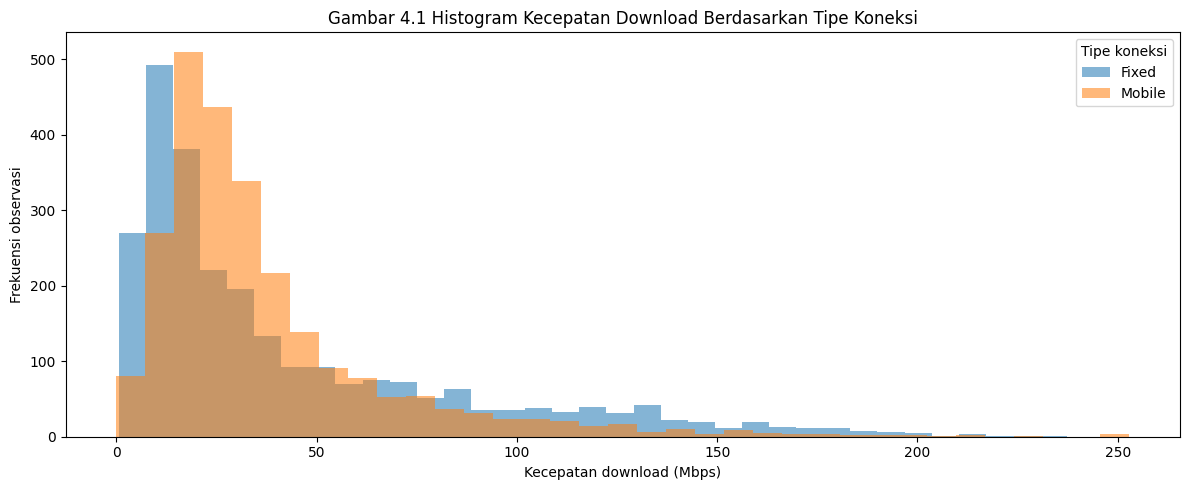

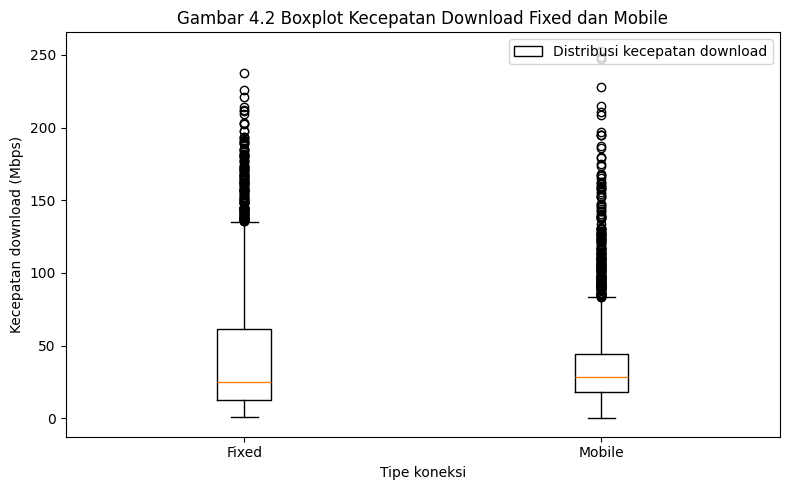

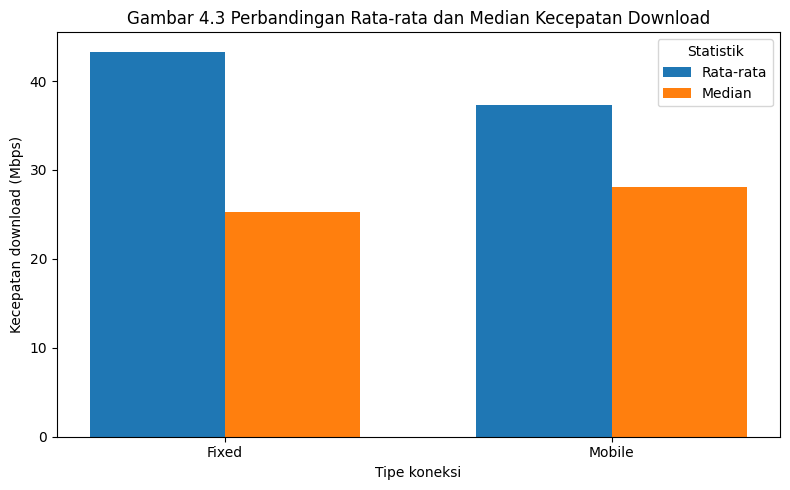

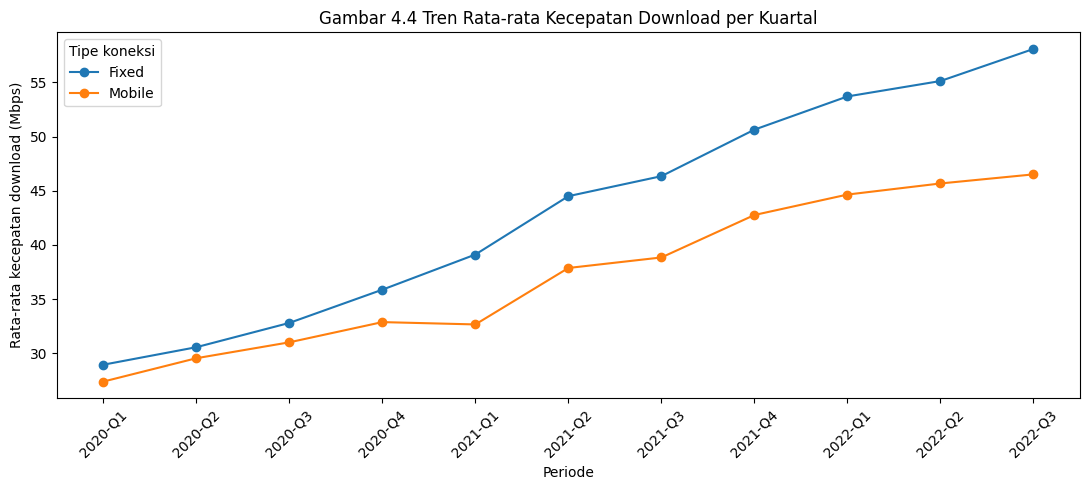

Grafik berhasil disimpan:
/content/speedtest_figures/gambar_4_1_histogram.png
/content/speedtest_figures/gambar_4_2_boxplot.png
/content/speedtest_figures/gambar_4_3_mean_median.png
/content/speedtest_figures/gambar_4_4_trend.png


In [ ]:
from matplotlib.patches import Patch

os.makedirs("/content/speedtest_figures", exist_ok=True)

fixed = clean.loc[
    clean["Connection Type"] == "Fixed",
    "Download Mbps"
]

mobile = clean.loc[
    clean["Connection Type"] == "Mobile",
    "Download Mbps"
]

# Gambar 4.1: Histogram Fixed dan Mobile
plt.figure(figsize=(12, 5))

for tipe in ["Fixed", "Mobile"]:
    nilai = clean.loc[
        clean["Connection Type"] == tipe,
        "Download Mbps"
    ]

    plt.hist(
        nilai,
        bins=35,
        alpha=0.55,
        label=tipe
    )

plt.title(
    "Gambar 4.1 Histogram Kecepatan Download "
    "Berdasarkan Tipe Koneksi"
)
plt.xlabel("Kecepatan download (Mbps)")
plt.ylabel("Frekuensi observasi")
plt.legend(title="Tipe koneksi")
plt.tight_layout()

plt.savefig(
    "/content/speedtest_figures/gambar_4_1_histogram.png",
    dpi=150
)
plt.show()


# Gambar 4.2: Boxplot Fixed dan Mobile
plt.figure(figsize=(8, 5))

plt.boxplot(
    [fixed, mobile],
    tick_labels=["Fixed", "Mobile"],
    showfliers=True
)

plt.title(
    "Gambar 4.2 Boxplot Kecepatan Download "
    "Fixed dan Mobile"
)
plt.xlabel("Tipe koneksi")
plt.ylabel("Kecepatan download (Mbps)")

plt.legend(
    handles=[
        Patch(
            facecolor="white",
            edgecolor="black",
            label="Distribusi kecepatan download"
        )
    ],
    loc="upper right"
)

plt.tight_layout()

plt.savefig(
    "/content/speedtest_figures/gambar_4_2_boxplot.png",
    dpi=150
)
plt.show()


# Gambar 4.3: Perbandingan rata-rata dan median
bar_stats = (
    clean.groupby("Connection Type")["Download Mbps"]
    .agg(["mean", "median"])
    .reindex(["Fixed", "Mobile"])
)

x = np.arange(2)
lebar = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - lebar / 2,
    bar_stats["mean"],
    lebar,
    label="Rata-rata"
)

plt.bar(
    x + lebar / 2,
    bar_stats["median"],
    lebar,
    label="Median"
)

plt.xticks(x, bar_stats.index)

plt.title(
    "Gambar 4.3 Perbandingan Rata-rata dan Median "
    "Kecepatan Download"
)
plt.xlabel("Tipe koneksi")
plt.ylabel("Kecepatan download (Mbps)")
plt.legend(title="Statistik")
plt.tight_layout()

plt.savefig(
    "/content/speedtest_figures/gambar_4_3_mean_median.png",
    dpi=150
)
plt.show()


# Gambar 4.4: Tren rata-rata per kuartal
plt.figure(figsize=(11, 5))

for tipe in ["Fixed", "Mobile"]:
    data_tren = trend[
        trend["Connection Type"] == tipe
    ].sort_values("Urutan periode")

    plt.plot(
        data_tren["Period"],
        data_tren["Download Mbps"],
        marker="o",
        label=tipe
    )

plt.title(
    "Gambar 4.4 Tren Rata-rata Kecepatan "
    "Download per Kuartal"
)
plt.xlabel("Periode")
plt.ylabel("Rata-rata kecepatan download (Mbps)")
plt.xticks(rotation=45)
plt.legend(title="Tipe koneksi")
plt.tight_layout()

plt.savefig(
    "/content/speedtest_figures/gambar_4_4_trend.png",
    dpi=150
)
plt.show()


# Daftar file grafik yang dihasilkan
print("Grafik berhasil disimpan:")
for file_path in sorted(
    glob.glob("/content/speedtest_figures/*.png")
):
    print(file_path)

# Uji t dua sampel independen **Welch**

In [ ]:
# Ambil nilai download setiap kelompok
fixed = clean.loc[
    clean["Connection Type"] == "Fixed",
    "Download Mbps"
].dropna()

mobile = clean.loc[
    clean["Connection Type"] == "Mobile",
    "Download Mbps"
].dropna()

# Uji t Welch
hasil_uji = stats.ttest_ind(
    fixed,
    mobile,
    equal_var=False
)

# Statistik sampel
n_fixed = len(fixed)
n_mobile = len(mobile)

mean_fixed = fixed.mean()
mean_mobile = mobile.mean()

var_fixed = fixed.var(ddof=1)
var_mobile = mobile.var(ddof=1)

# Derajat kebebasan Welch-Satterthwaite
komponen_fixed = var_fixed / n_fixed
komponen_mobile = var_mobile / n_mobile

df_welch = (
    (komponen_fixed + komponen_mobile) ** 2
    /
    (
        komponen_fixed ** 2 / (n_fixed - 1)
        +
        komponen_mobile ** 2 / (n_mobile - 1)
    )
)

alpha = 0.05

keputusan = (
    "Menolak H0"
    if hasil_uji.pvalue < alpha
    else "Tidak menolak H0"
)

print("HASIL UJI T DUA SAMPEL INDEPENDEN WELCH")
print(f"n Fixed              : {n_fixed}")
print(f"n Mobile             : {n_mobile}")
print(f"Rata-rata Fixed      : {mean_fixed:.6f} Mbps")
print(f"Rata-rata Mobile     : {mean_mobile:.6f} Mbps")
print(
    f"Selisih rata-rata    : "
    f"{mean_fixed - mean_mobile:.6f} Mbps"
)
print(f"t hitung             : {hasil_uji.statistic:.9f}")
print(f"Derajat kebebasan    : {df_welch:.6f}")
print(f"p-value              : {hasil_uji.pvalue:.12g}")
print(f"Taraf signifikansi   : {alpha}")
print(f"Keputusan            : {keputusan}")

print("\nH0: Rata-rata Fixed = rata-rata Mobile")
print("H1: Rata-rata Fixed berbeda dari rata-rata Mobile")

if hasil_uji.pvalue < alpha:
    print(
        "Kesimpulan: terdapat perbedaan rata-rata "
        "kecepatan download yang signifikan secara "
        "statistik pada taraf 0,05."
    )
else:
    print(
        "Kesimpulan: belum terdapat bukti yang cukup "
        "untuk menyatakan rata-rata kedua kelompok berbeda "
        "pada taraf 0,05."
    )

HASIL UJI T DUA SAMPEL INDEPENDEN WELCH
n Fixed              : 2597
n Mobile             : 2487
Rata-rata Fixed      : 43.308986 Mbps
Rata-rata Mobile     : 37.323619 Mbps
Selisih rata-rata    : 5.985367 Mbps
t hitung             : 5.683949539
Derajat kebebasan    : 4706.341902
p-value              : 1.3955829104e-08
Taraf signifikansi   : 0.05
Keputusan            : Menolak H0

H0: Rata-rata Fixed = rata-rata Mobile
H1: Rata-rata Fixed berbeda dari rata-rata Mobile
Kesimpulan: terdapat perbedaan rata-rata kecepatan download yang signifikan secara statistik pada taraf 0,05.
